In [4]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

# Uploaded CSV file select
csv_file = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

# Load dataset
df = pd.read_csv(csv_file)

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLoan status distribution:")
print(df["loan_status"].value_counts(dropna=False))

Saving archive.zip to archive.zip


StopIteration: 

In [5]:
import os
import zipfile
from pathlib import Path
import pandas as pd

# ZIP file extract করা
zip_path = "/content/archive.zip"
extract_dir = "/content/loan_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

# ZIP-এর ভেতরে CSV file খোঁজা
csv_files = [
    f for f in Path(extract_dir).rglob("*")
    if f.is_file() and f.suffix.lower() == ".csv"
]

print("CSV files found:")
for f in csv_files:
    print(f)

if not csv_files:
    raise FileNotFoundError(
        "ZIP-এর ভেতরে কোনো CSV file পাওয়া যায়নি।"
    )

# Loan dataset বেছে নেওয়া
preferred = [
    f for f in csv_files
    if "loan_approval_dataset" in f.name.lower()
]

csv_file = preferred[0] if preferred else csv_files[0]

# Dataset load করা
df = pd.read_csv(csv_file)

# Column name পরিষ্কার করা
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("\nDataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLoan status distribution:")
if "loan_status" in df.columns:
    print(df["loan_status"].value_counts(dropna=False))
else:
    print("Target column পাওয়া যায়নি। Columns:", df.columns.tolist())

CSV files found:
/content/loan_data/train.csv
/content/loan_data/loan_approval_dataset.csv
/content/loan_data/sample_submission.csv
/content/loan_data/test.csv

Dataset shape: (4269, 13)

First 5 rows:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB

Missing 

Dataset shape: (4269, 13)

Missing values in dataset:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Total missing values: 0

Duplicate rows: 0

Duplicate loan IDs: 0

Loan Status Counts:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Loan Status Percentage:
loan_status
Approved    62.22
Rejected    37.78
Name: proportion, dtype: float64

education categories:
education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

self_employed categories:
self_employed
Yes    2150
No     2119
Name: count, dtype: int64

Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
no_of_dependents,4269.0,2.50,1.70,0.0,1.0,3.0,4.0,5.0
income_annum,4269.0,5059123.92,2806839.83,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,15133450.46,9043362.98,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,10.90,5.71,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,599.94,172.43,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,7472616.54,6503636.59,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,4973155.31,4388966.09,0.0,1300000.0,3700000.0,7600000.0,19400000.0
luxury_assets_value,4269.0,15126305.93,9103753.67,300000.0,7500000.0,14600000.0,21700000.0,39200000.0
bank_asset_value,4269.0,4976692.43,3250185.31,0.0,2300000.0,4600000.0,7100000.0,14700000.0


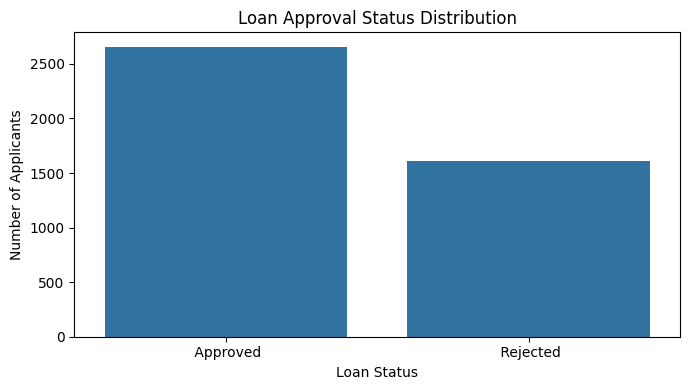

In [6]:
# Step 3: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dataset size
print("Dataset shape:", df.shape)

# 2. Missing values
print("\nMissing values in dataset:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# 3. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check loan IDs
print("\nDuplicate loan IDs:", df["loan_id"].duplicated().sum())

# 5. Target distribution
print("\nLoan Status Counts:")
print(df["loan_status"].value_counts())

print("\nLoan Status Percentage:")
print(
    (df["loan_status"].value_counts(normalize=True) * 100)
    .round(2)
)

# 6. Categorical feature values
for col in ["education", "self_employed"]:
    print(f"\n{col} categories:")
    print(df[col].value_counts())

# 7. Numerical feature statistics
print("\nNumerical Feature Statistics:")
display(
    df.select_dtypes(include="number")
      .drop(columns=["loan_id"], errors="ignore")
      .describe()
      .T
      .round(2)
)

# 8. Visualize target distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="loan_status")
plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

Negative values in asset columns:
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64

Rows containing negative asset values: 28


,loan_id,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,-100000,4900000,18600000,4800000,Approved
196,197,-100000,600000,900000,500000,Approved
559,560,-100000,0,300000,200000,Rejected
702,703,-100000,11400000,20600000,6700000,Approved
737,738,-100000,100000,3200000,1100000,Rejected
784,785,-100000,7300000,12600000,4500000,Approved
904,905,-100000,5200000,13000000,3400000,Approved
1089,1090,-100000,5800000,11600000,7500000,Rejected
1163,1164,-100000,600000,12400000,2500000,Approved
1350,1351,-100000,1400000,15800000,3700000,Rejected



Potential outliers (IQR method):
income_annum: 0 potential outliers
loan_amount: 0 potential outliers
cibil_score: 0 potential outliers
residential_assets_value: 52 potential outliers
commercial_assets_value: 37 potential outliers
luxury_assets_value: 0 potential outliers
bank_asset_value: 5 potential outliers


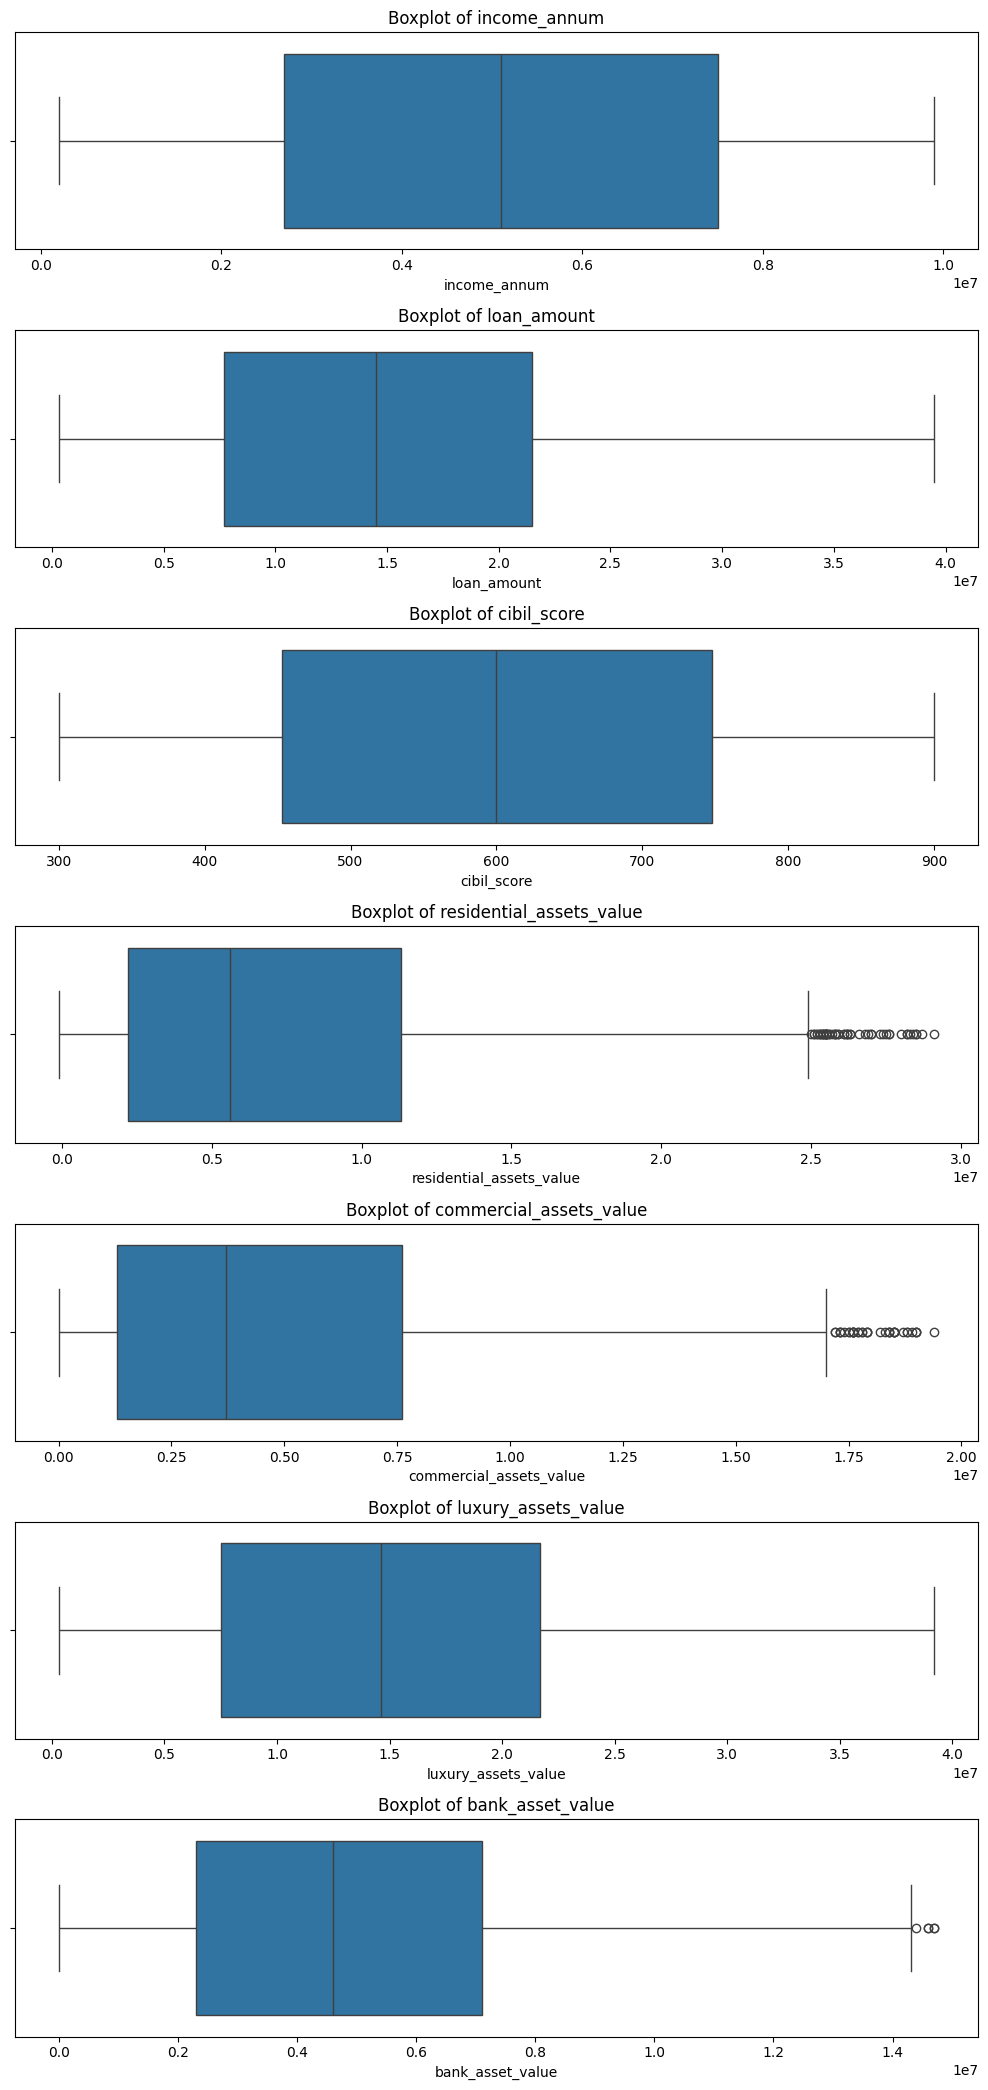

In [7]:
# Step 4: Data Cleaning and Outlier Checking

import matplotlib.pyplot as plt
import seaborn as sns

# Asset-related features
asset_cols = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

# 1. Check negative asset values
print("Negative values in asset columns:")
print(df[asset_cols].lt(0).sum())

# 2. Display rows with negative asset values
negative_mask = (df[asset_cols] < 0).any(axis=1)

print("\nRows containing negative asset values:",
      negative_mask.sum())

display(
    df.loc[
        negative_mask,
        ["loan_id"] + asset_cols + ["loan_status"]
    ]
)

# 3. Identify possible outliers using the IQR rule
numeric_cols = [
    "income_annum",
    "loan_amount",
    "cibil_score",
    *asset_cols
]

print("\nPotential outliers (IQR method):")

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    count = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ).sum()

    print(f"{col}: {count} potential outliers")

# 4. Visualize distributions with boxplots
fig, axes = plt.subplots(
    len(numeric_cols), 1,
    figsize=(10, 3 * len(numeric_cols))
)

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [8]:
# Step 5: Remove records with negative asset values

asset_cols = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

# Keep rows where every asset value is non-negative
negative_mask = (df[asset_cols] < 0).any(axis=1)

df_clean = df.loc[~negative_mask].copy()

print("Original dataset shape:", df.shape)
print("Rows removed:", negative_mask.sum())
print("Cleaned dataset shape:", df_clean.shape)

print("\nNegative asset values after cleaning:")
print(df_clean[asset_cols].lt(0).sum())

print("\nLoan status distribution after cleaning:")
print(df_clean["loan_status"].value_counts())

print("\nMissing values after cleaning:",
      df_clean.isnull().sum().sum())

print("\nDuplicate rows after cleaning:",
      df_clean.duplicated().sum())

Original dataset shape: (4269, 13)
Rows removed: 28
Cleaned dataset shape: (4241, 13)

Negative asset values after cleaning:
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
dtype: int64

Loan status distribution after cleaning:
loan_status
Approved    2640
Rejected    1601
Name: count, dtype: int64

Missing values after cleaning: 0

Duplicate rows after cleaning: 0


In [9]:
# Step 6: Feature Selection and Data Splitting

from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df_clean.drop(columns=["loan_id", "loan_status"])
y = df_clean["loan_status"].str.strip()

print("Feature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: split the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display split sizes
print("\nTraining set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

# Verify class distribution in each subset
for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name} class distribution:")
    print(target.value_counts())
    print(
        (target.value_counts(normalize=True) * 100).round(2)
    )

Feature columns:
['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

Target classes:
loan_status
Approved    2640
Rejected    1601
Name: count, dtype: int64

Training set: (2968, 11)
Validation set: (636, 11)
Test set: (637, 11)

Training class distribution:
loan_status
Approved    1848
Rejected    1120
Name: count, dtype: int64
loan_status
Approved    62.26
Rejected    37.74
Name: proportion, dtype: float64

Validation class distribution:
loan_status
Approved    396
Rejected    240
Name: count, dtype: int64
loan_status
Approved    62.26
Rejected    37.74
Name: proportion, dtype: float64

Test class distribution:
loan_status
Approved    396
Rejected    241
Name: count, dtype: int64
loan_status
Approved    62.17
Rejected    37.83
Name: proportion, dtype: float64


In [10]:
# Step 7: Preprocessing, Encoding and Scaling

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# 2. Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="if_binary"
    ))
])

# 4. Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 5. Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# 6. Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# 7. Encode target: Rejected = 0, Approved = 1
target_mapping = {
    "Rejected": 0,
    "Approved": 1
}

y_train_encoded = y_train.map(target_mapping)
y_val_encoded = y_val.map(target_mapping)
y_test_encoded = y_test.map(target_mapping)

# 8. Check the results
print("\nProcessed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nEncoded feature names:")
print(preprocessor.get_feature_names_out().tolist())

print("\nTarget encoding:")
print(target_mapping)

print("\nTraining target counts:")
print(y_train_encoded.value_counts())

Numerical features: ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

Categorical features: ['education', 'self_employed']

Processed training shape: (2968, 11)
Processed validation shape: (636, 11)
Processed test shape: (637, 11)

Encoded feature names:
['num__no_of_dependents', 'num__income_annum', 'num__loan_amount', 'num__loan_term', 'num__cibil_score', 'num__residential_assets_value', 'num__commercial_assets_value', 'num__luxury_assets_value', 'num__bank_asset_value', 'cat__education_ Not Graduate', 'cat__self_employed_ Yes']

Target encoding:
{'Rejected': 0, 'Approved': 1}

Training target counts:
loan_status
1    1848
0    1120
Name: count, dtype: int64


Processed training shape: (2968, 11)
Encoded feature names:
['num__no_of_dependents', 'num__income_annum', 'num__loan_amount', 'num__loan_term', 'num__cibil_score', 'num__residential_assets_value', 'num__commercial_assets_value', 'num__luxury_assets_value', 'num__bank_asset_value', 'cat__education_Not Graduate', 'cat__self_employed_Yes']

Logistic Regression
Validation Accuracy: 0.9230
Validation Precision: 0.9437
Validation Recall: 0.9318
Validation F1-score: 0.9377
Validation ROC-AUC: 0.9660

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.89      0.91      0.90       240
    Approved       0.94      0.93      0.94       396

    accuracy                           0.92       636
   macro avg       0.92      0.92      0.92       636
weighted avg       0.92      0.92      0.92       636


Decision Tree
Validation Accuracy: 0.9780
Validation Precision: 0.9848
Validation Recall: 0.9798
Validation F1-score: 0.9823
Validation ROC-AUC: 0.97

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9230,0.9437,0.9318,0.9377,0.9660
1,Decision Tree,0.9780,0.9848,0.9798,0.9823,0.9774
2,Random Forest,0.9811,0.9848,0.9848,0.9848,0.9974


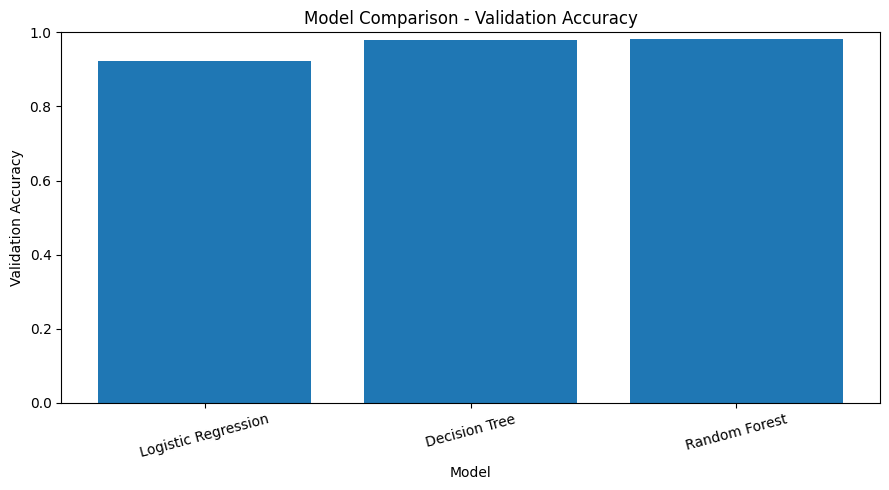

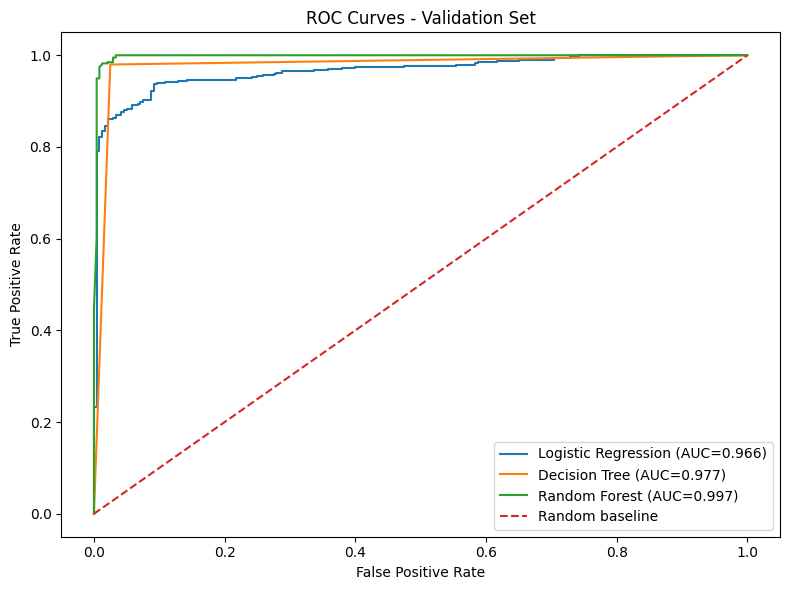

In [11]:
# Step 8: Model Training and Validation

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

# 1. Clean categorical text
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

for frame in [X_train, X_val, X_test]:
    for col in categorical_features:
        frame[col] = frame[col].astype(str).str.strip()

# 2. Refit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Encoded feature names:")
print(preprocessor.get_feature_names_out().tolist())

# 3. Define models
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# 4. Train models and evaluate on validation data
results = []
trained_models = {}

for name, model in classifiers.items():

    model.fit(X_train_processed, y_train_encoded)

    val_pred = model.predict(X_val_processed)
    val_prob = model.predict_proba(X_val_processed)[:, 1]

    accuracy = accuracy_score(y_val_encoded, val_pred)
    precision = precision_score(
        y_val_encoded, val_pred, zero_division=0
    )
    recall = recall_score(
        y_val_encoded, val_pred, zero_division=0
    )
    f1 = f1_score(
        y_val_encoded, val_pred, zero_division=0
    )
    auc = roc_auc_score(y_val_encoded, val_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = model

    print(f"\n{'=' * 45}")
    print(name)
    print(f"Validation Accuracy: {accuracy:.4f}")
    print(f"Validation Precision: {precision:.4f}")
    print(f"Validation Recall: {recall:.4f}")
    print(f"Validation F1-score: {f1:.4f}")
    print(f"Validation ROC-AUC: {auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_val_encoded,
        val_pred,
        labels=[0, 1],
        target_names=["Rejected", "Approved"],
        zero_division=0
    ))

# 5. Compare validation scores
results_df = pd.DataFrame(results)

print("\nValidation Model Comparison:")
display(results_df.round(4))

# 6. Validation accuracy comparison chart
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.title("Model Comparison - Validation Accuracy")
plt.xlabel("Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 7. ROC curves using validation data
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():
    val_prob = model.predict_proba(X_val_processed)[:, 1]

    fpr, tpr, _ = roc_curve(y_val_encoded, val_prob)
    auc = roc_auc_score(y_val_encoded, val_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title("ROC Curves - Validation Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

Final Test Results — Random Forest


,Metric,Test Score
0,Accuracy,0.9890
1,Precision,0.9875
2,Recall,0.9949
3,F1-score,0.9912
4,ROC-AUC,0.9981



Classification Report:
              precision    recall  f1-score   support

    Rejected       0.99      0.98      0.99       241
    Approved       0.99      0.99      0.99       396

    accuracy                           0.99       637
   macro avg       0.99      0.99      0.99       637
weighted avg       0.99      0.99      0.99       637



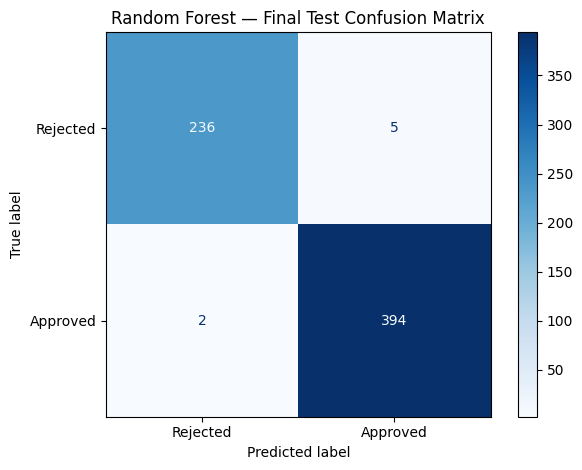

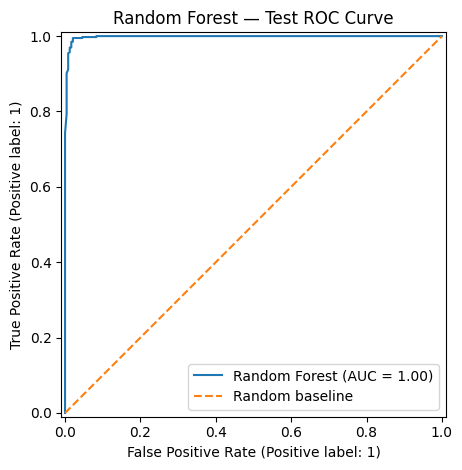

In [12]:
# Step 9: Final Evaluation on the Test Set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Select the best model based on validation results
best_model = trained_models["Random Forest"]

# Predict on unseen test data
y_test_pred = best_model.predict(X_test_processed)
y_test_prob = best_model.predict_proba(X_test_processed)[:, 1]

# Calculate final evaluation metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test_encoded, y_test_pred),
    "Precision": precision_score(
        y_test_encoded, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test_encoded, y_test_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test_encoded, y_test_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test_encoded, y_test_prob)
}

print("Final Test Results — Random Forest")
display(
    pd.DataFrame(
        test_metrics.items(),
        columns=["Metric", "Test Score"]
    ).round(4)
)

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_test_pred,
    labels=[0, 1],
    target_names=["Rejected", "Approved"],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded,
    y_test_pred,
    labels=[0, 1],
    display_labels=["Rejected", "Approved"],
    cmap="Blues"
)
plt.title("Random Forest — Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

# ROC curve on the test set
RocCurveDisplay.from_predictions(
    y_test_encoded,
    y_test_prob,
    name="Random Forest"
)
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.title("Random Forest — Test ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

Random Forest Feature Importance:


,Feature,Importance
4,num__cibil_score,0.8181
3,num__loan_term,0.0568
2,num__loan_amount,0.0293
7,num__luxury_assets_value,0.0181
1,num__income_annum,0.0172
6,num__commercial_assets_value,0.0166
8,num__bank_asset_value,0.0154
5,num__residential_assets_value,0.0153
0,num__no_of_dependents,0.0083
10,cat__self_employed_Yes,0.0026


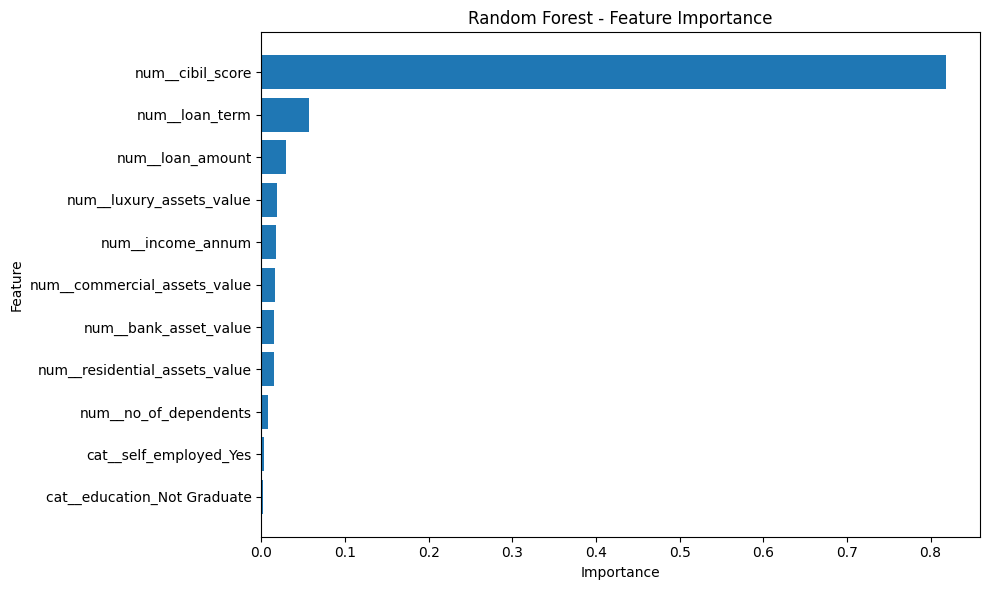

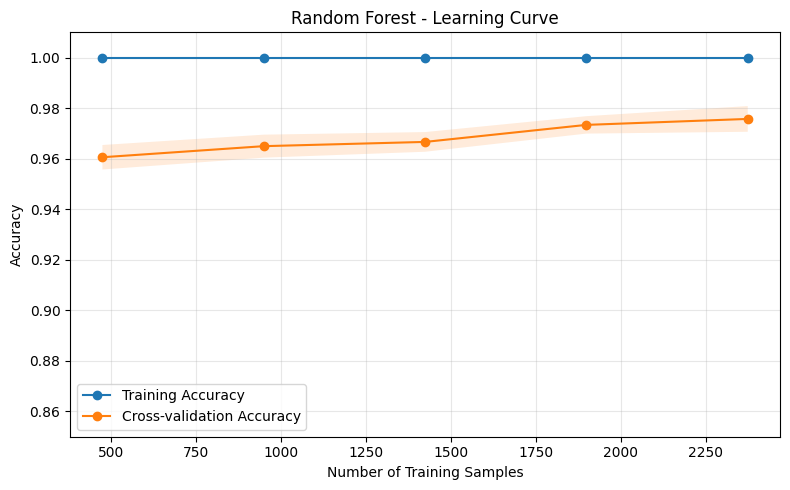

In [13]:
# Step 10: Feature Importance and Learning Curve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import learning_curve

# ------------------------------------------
# Part A: Feature Importance
# ------------------------------------------

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Random Forest Feature Importance:")
display(importance_df.round(4))

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# ------------------------------------------
# Part B: Learning Curve
# ------------------------------------------

# Preprocessing and model are placed in one pipeline.
# Each CV fold fits its own preprocessing steps.
learning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_pipeline,
    X_train,
    y_train_encoded,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes, train_mean,
    marker="o", label="Training Accuracy"
)
plt.plot(
    train_sizes, val_mean,
    marker="o", label="Cross-validation Accuracy"
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

plt.title("Random Forest - Learning Curve")
plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.ylim(0.85, 1.01)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Step 11: Final Results Summary

import pandas as pd
from google.colab import files

# Validation results from Step 8
final_results = results_df.rename(columns={
    "Accuracy": "Validation Accuracy",
    "Precision": "Validation Precision",
    "Recall": "Validation Recall",
    "F1-score": "Validation F1-score",
    "ROC-AUC": "Validation ROC-AUC"
}).copy()

# Add final test metrics (only for the selected model)
test_columns = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1-score",
    "Test ROC-AUC"
]

for col in test_columns:
    final_results[col] = float("nan")

rf_index = final_results.index[
    final_results["Model"] == "Random Forest"
]

for metric, value in test_metrics.items():
    final_results.loc[rf_index, f"Test {metric}"] = value

print("Final Model Comparison")
display(final_results.round(4))

# Export results
output_file = "loan_approval_final_results.csv"
final_results.to_csv(output_file, index=False)

print("\nResults saved:", output_file)

# Download the results CSV
files.download(output_file)

Final Model Comparison


,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-score,Validation ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1-score,Test ROC-AUC
0,Logistic Regression,0.9230,0.9437,0.9318,0.9377,0.9660,NaN,NaN,NaN,NaN,NaN
1,Decision Tree,0.9780,0.9848,0.9798,0.9823,0.9774,NaN,NaN,NaN,NaN,NaN
2,Random Forest,0.9811,0.9848,0.9848,0.9848,0.9974,0.989,0.9875,0.9949,0.9912,0.9981



Results saved: loan_approval_final_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
%pip -q install gradio

In [16]:
import pandas as pd
import gradio as gr

def predict_loan(
    no_of_dependents,
    education,
    self_employed,
    income_annum,
    loan_amount,
    loan_term,
    cibil_score,
    residential_assets_value,
    commercial_assets_value,
    luxury_assets_value,
    bank_asset_value
):
    # Collect applicant inputs
    applicant = pd.DataFrame([{
        "no_of_dependents": no_of_dependents,
        "education": education,
        "self_employed": self_employed,
        "income_annum": income_annum,
        "loan_amount": loan_amount,
        "loan_term": loan_term,
        "cibil_score": cibil_score,
        "residential_assets_value": residential_assets_value,
        "commercial_assets_value": commercial_assets_value,
        "luxury_assets_value": luxury_assets_value,
        "bank_asset_value": bank_asset_value
    }])

    # Apply the same preprocessing used during training
    processed = preprocessor.transform(applicant)

    # Predict with the trained Random Forest
    prediction = int(best_model.predict(processed)[0])
    probabilities = best_model.predict_proba(processed)[0]

    probability_by_class = dict(
        zip(best_model.classes_, probabilities)
    )

    approval_probability = float(probability_by_class[1]) * 100

    status = "Approved" if prediction == 1 else "Rejected"

    result = (
        f"### Predicted Loan Status: {status}\n\n"
        "This is the trained model's prediction, "
        "not an actual bank decision."
    )

    return result, round(approval_probability, 2)


demo = gr.Interface(
    fn=predict_loan,
    inputs=[
        gr.Number(label="Number of Dependents", value=2),
        gr.Dropdown(
            ["Graduate", "Not Graduate"],
            label="Education",
            value="Graduate"
        ),
        gr.Dropdown(
            ["Yes", "No"],
            label="Self Employed",
            value="No"
        ),
        gr.Number(label="Annual Income", value=5000000),
        gr.Number(label="Loan Amount", value=15000000),
        gr.Number(label="Loan Term", value=10),
        gr.Number(label="CIBIL Score", value=700),
        gr.Number(label="Residential Assets Value", value=5000000),
        gr.Number(label="Commercial Assets Value", value=2000000),
        gr.Number(label="Luxury Assets Value", value=8000000),
        gr.Number(label="Bank Asset Value", value=3000000)
    ],
    outputs=[
        gr.Markdown(label="Prediction"),
        gr.Number(label="Estimated Approval Probability (%)")
    ],
    title="Loan Approval Prediction System",
    description=(
        "Enter applicant details and click Submit to obtain "
        "a prediction from the trained Random Forest model."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8d346622231600681f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
